# Cite the Table Cell, Not the Page

Find the exact table cell behind a figure, read its row and column labels, check a claimed value against it, and show the cell in its table.

Companion notebook for the article [Cite the Table Cell, Not the Page](https://pymupdf.io/blog/cite-the-table-cell-not-the-page) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [2]:
import pymupdf
doc = pymupdf.open(); page = doc.new_page()
page.insert_text((72, 90), "Acme Corporation Annual Report 2025", fontsize=16, fontname="hebo")
page.insert_text((72, 125), "Consolidated statement of operations (in $ millions)", fontsize=12, fontname="hebo")
rows = [["", "2025", "2024", "Change"],
        ["Net revenue", "4,100", "3,661", "12%"],
        ["Gross profit", "2,870", "2,490", "15%"],
        ["Operating income", "754", "619", "22%"],
        ["Net income", "512", "430", "19%"]]
x = [72, 232, 322, 412, 502]; y0, h = 140, 22
for i, row in enumerate(rows):
    for j, cell in enumerate(row):
        r = pymupdf.Rect(x[j], y0 + i*h, x[j+1], y0 + (i+1)*h)
        page.draw_rect(r, color=(0, 0, 0), width=0.5)
        if cell:
            font = "hebo" if i == 0 or j == 0 else "helv"
            align = 0 if j == 0 else 2
            page.insert_textbox(r + (4, 5, -4, 0), cell, fontsize=10, fontname=font, align=align)
page.insert_textbox(pymupdf.Rect(72, 270, 502, 400), "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. Operating income rose 22%, and the operating margin improved to 18.4%.", fontsize=11, fontname="helv")
doc.save("acme_financials.pdf")

## Step 1: Read the table cells

`Page.find_tables()` detects the tables on a page. Each table has rows, and each row has the bounding box of every cell. We read each cell's text with `Page.get_text(clip=...)`, so the text matches what the rest of PyMuPDF returns for that area of the page. Merged cells appear as `None`.

In [3]:
import re
import pymupdf


def table_grid(page, table):
    """Text and bbox of every cell in a table, as a list of rows."""
    grid = []
    for row in table.rows:
        cells = []
        for bbox in row.cells:
            if bbox is None:                       # part of a merged cell
                cells.append(None)
                continue
            rect = pymupdf.Rect(bbox)
            text = " ".join(page.get_text("text", clip=rect).split())
            cells.append({"text": text, "bbox": rect})
        grid.append(cells)
    return grid

## Step 2: Find a value and its labels

Numbers in tables come in many formats: "4,100", "$1,234.5", "12%", or "(52)" for a negative value. Comparing them as numbers avoids false misses. For each matching cell we return its position, its bounding box, and the labels in the first column and the header row.

In [4]:
def to_number(text):
    """'4,100' -> 4100.0, '(52)' -> -52.0, '12%' -> 12.0; None if not a number."""
    t = text.replace(",", "").replace("$", "").replace("%", "").strip()
    if re.fullmatch(r"\(\d+(\.\d+)?\)", t):
        t = "-" + t[1:-1]
    try:
        return float(t)
    except ValueError:
        return None

In [5]:
def _labels(grid, r, c):
    row_label = grid[r][0]["text"] if grid[r][0] else ""
    col_label = grid[0][c]["text"] if grid[0][c] else ""
    return row_label, col_label

In [6]:
def find_value(page, value):
    """Every table cell on the page that holds value, with its row and column labels."""
    target = to_number(str(value))
    hits = []
    for t_index, table in enumerate(page.find_tables().tables):
        grid = table_grid(page, table)
        for r, row in enumerate(grid):
            for c, cell in enumerate(row):
                if cell is None:
                    continue
                n = to_number(cell["text"])
                same = (n == target) if target is not None else cell["text"] == str(value)
                if same:
                    row_label, col_label = _labels(grid, r, c)
                    hits.append({"table": t_index, "row": r, "col": c, "text": cell["text"],
                                 "bbox": cell["bbox"], "row_label": row_label,
                                 "col_label": col_label, "table_bbox": pymupdf.Rect(table.bbox)})
    return hits

In [7]:
doc = pymupdf.open("acme_financials.pdf")
page = doc[0]
for hit in find_value(page, "754"):
    print(f'{hit["text"]}: {hit["row_label"]}, {hit["col_label"]} (page {page.number + 1}, table {hit["table"] + 1})')

754: Operating income, 2025 (page 1, table 1)


If a value appears in several cells, you get every match with its labels, and the labels tell you which one the answer meant.

## Step 3: Check a claimed figure by its labels

To verify an answer, go the other way: look up the cell where a row label and a column label meet, and compare the value.

In [8]:
def lookup(page, row_label, col_label):
    """The cell where a row label and a column label meet, or None."""
    for t_index, table in enumerate(page.find_tables().tables):
        grid = table_grid(page, table)
        header = [cell["text"].lower() if cell else "" for cell in grid[0]]
        cols = [c for c, h in enumerate(header) if col_label.lower() in h]
        for r, row in enumerate(grid[1:], start=1):
            if row[0] and row_label.lower() in row[0]["text"].lower():
                for c in cols:
                    if row[c]:
                        return {"table": t_index, "row": r, "col": c, "text": row[c]["text"],
                                "bbox": row[c]["bbox"], "row_label": row[0]["text"],
                                "col_label": grid[0][c]["text"], "table_bbox": pymupdf.Rect(table.bbox)}
    return None

In [9]:
cell = lookup(page, "Net revenue", "2025")
claimed = 4100                      # "$4.1 billion", in the table's unit ($ millions)
print(cell["text"], to_number(cell["text"]) == claimed)      # 4,100 True

cell = lookup(page, "Operating income", "2025")
print(cell["text"], to_number(cell["text"]) == 760)          # 754 False: flag for review

4,100 True
754 False


Units usually come from the table's caption, such as "in $ millions" in the sample report. Convert the claimed figure to the table's unit before comparing.

## Step 4: Show the cell in its table

A reader checks a figure fastest when they see it in context: the whole table, with the cited cell marked. This function draws a temporary marker on the cell, renders the table and removes the marker again, so the document is left unchanged.

In [10]:
def cell_image(page, hit, dpi=150, margin=8):
    """Render the whole table with the cited cell highlighted; the page is left unchanged."""
    annot = page.add_rect_annot(hit["bbox"])               # temporary marker on the cell
    annot.set_colors(stroke=(0.9, 0.5, 0), fill=(1, 0.9, 0))
    annot.set_border(width=1.5)
    annot.set_opacity(0.5)
    annot.update()
    clip = (hit["table_bbox"] + (-margin, -margin, margin, margin)) & page.rect
    pix = page.get_pixmap(clip=clip, dpi=dpi)
    page.delete_annot(annot)
    return pix

In [11]:
cell_image(page, lookup(page, "Net revenue", "2025")).save("evidence_cell.png")

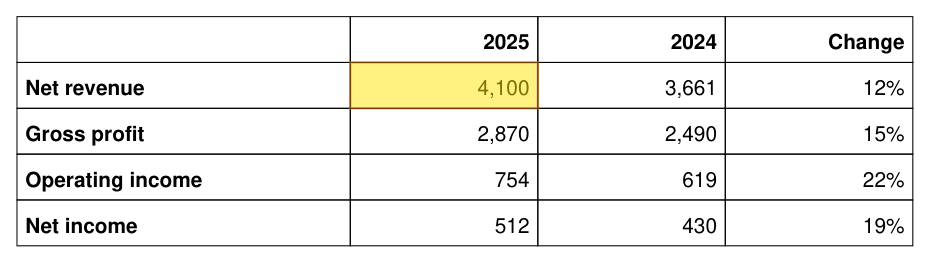

In [12]:
from IPython.display import Image, display
display(Image("evidence_cell.png"))

## Connecting it to an AI answer

Text citations work well for sentences, but they suit tables less well: a model quoting a table often reproduces a flattened row of text. Two approaches work better for figures.
- **Use the cited page as a filter.** With Claude citations, take the page from `start_page_number` and call `find_value()` on that page only. The labels of each match show whether it is the figure the answer meant.
- **Ask the model for table references.** Add an instruction such as the one below to your prompt, then call `lookup()` for each reference and compare the values.

```
For every figure you report from a table, add a line in this form:
TABLE: page=<page number> | row=<row label> | column=<column label> | value=<value as printed>
```

## Limits to know
- Table detection works best on tables with ruling lines. For tables without lines, check the results, and try `page.find_tables(strategy="text")`.
- Labels come from the first column and the first row. Tables with multi-level headers or labels spread over several cells need extra handling.
- Merged cells return None for the covered positions.
- Units and scale (thousands, millions) are in captions and footnotes, not in the cells. Handle them before comparing values.

## Next steps

- Read the full article: https://pymupdf.io/blog/cite-the-table-cell-not-the-page
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding